# S1_02 : Completion causal forests and policy trees

Run after the S1_01 preparation master. This notebook reads the newest completed, source-linked residential and outpatient runs. It evaluates two separate service-setting contrasts. The main diagnostic retains all eligible completion episodes and represents missing admission covariates as observed categories. A separate complete-case analysis measures sensitivity to that choice. Neither coding recovers unobserved covariate values; outcome-assisted full-sample validation imputation draws cannot be used for honest held-out policy evaluation because they include held-out outcomes.

Within each branch and sample, use fixed 60/20/20 train/tree-build/held-out splits. Fit nuisance models and a causal forest on training episodes, build an overlap-weighted doubly robust policy tree on separate episodes, and freeze it before using evaluation outcomes. Report values relative to constant treatment rules, state omission, and held-out CATE quartiles. Separately train the outpatient eligible tree only on 2022 and evaluate it on 2023 as a temporal diagnostic. A sensitivity tree replaces missing policy inputs with training-set modes, without changing the nuisance models or eligible episodes. These are observational diagnostics with no final multiple-imputation or state-level inference.

In [1]:
from pathlib import Path
from datetime import datetime
import gc, hashlib, json, os, platform, sys, time
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import joblib
from scipy.stats import t as student_t
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from econml.dml import CausalForestDML
from econml.policy import PolicyTree
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/stage1_specifications.json').is_file())
HOME=ROOT/'S1'
FIXED_OUTPUTS=Path(os.environ.get('REPLICATION_S1_FIXED_OUTPUTS',ROOT/'S1/fixed_inputs')).resolve()
sys.path.insert(0,str(HOME/'helper'))
from reporting import Review
SPEC=json.loads((HOME/'helper/assets/sample_specification.json').read_text())
X_FIELDS=[x for x in SPEC['fields'] if x not in ('STFIPS','DISYR')]
OUTPUTS=HOME/'outputs';REPORTS=HOME/'reports'
OUTPUTS.mkdir(parents=True,exist_ok=True);REPORTS.mkdir(parents=True,exist_ok=True)
def sha(path):
    with Path(path).open('rb') as f:return hashlib.file_digest(f,'sha256').hexdigest()
COMPLETE_STATUSES={
 'S1_01_data_preparation':{'verified_samples_and_imputation_draws'},
 'S1_02_outcome_review':{'descriptive_review_complete_inference_pending'},
 'S1_03_outpatient_data_preparation':{'candidate_membership_and_four_imputation_draws_verified','candidate_membership_and_four_imputation_draws_verified_overlap_review_required'},
 'S1_04_outpatient_outcome_review':{'descriptive_review_complete_readiness_issues_identified'},
}
def newest(prefix):
    for p in sorted(FIXED_OUTPUTS.glob(prefix+'_*'),reverse=True):
        manifest=p/'manifest.json'
        if manifest.is_file():
            m=json.loads(manifest.read_text())
            if m.get('status') in COMPLETE_STATUSES[prefix]:return p,m
    raise FileNotFoundError(f'No complete {prefix} run under fixed input folder: {FIXED_OUTPUTS}')
res,m_res=newest('S1_01_data_preparation')
res_review,m_rr=newest('S1_02_outcome_review')
out,m_out=newest('S1_03_outpatient_data_preparation')
out_review,m_or=newest('S1_04_outpatient_outcome_review')
assert m_res['status']=='verified_samples_and_imputation_draws'
assert m_rr['status']=='descriptive_review_complete_inference_pending'
assert m_out['status'] in {'candidate_membership_and_four_imputation_draws_verified','candidate_membership_and_four_imputation_draws_verified_overlap_review_required'}
assert m_out['analysis_role']=='primary_14_state' and len(m_out['states'])==14
assert m_or['status']=='descriptive_review_complete_readiness_issues_identified'
for review,manifest,source in [(res_review,m_rr,res),(out_review,m_or,out)]:
    assert manifest['source_run']==source.name
    assert manifest['source_manifest_sha256']==sha(source/'manifest.json')
assert m_or['output_sha256']==sha(out_review/m_or['output_file'])
assert all(sha(res/name)==meta['sha256'] for name,meta in m_res['outputs'].items())
assert all(sha(out/item['file'])==item['sha256'] for item in m_out['imputation']['draws'])
BRANCHES={
 'residential':{'source':res,'treatment_0':'short-term residential','treatment_1':'long-term residential',
                'eligible_file':res/'completion_final_eligible.csv.gz',
                'complete_case_file':res/'completion_final_complete_case.csv.gz',
                'eligible_n':m_res['outputs']['completion_final_eligible.csv.gz']['n'],
                'complete_case_n':m_res['outputs']['completion_final_complete_case.csv.gz']['n']},
 'outpatient':{'source':out,'treatment_0':'non-intensive outpatient','treatment_1':'intensive outpatient',
               'eligible_file':out/'completion_final_eligible.csv.gz',
               'complete_case_file':out/'completion_final_eligible.csv.gz',
               'eligible_n':next(x['n'] for x in m_out['samples'] if x['outcome']=='completion'),
               'complete_case_n':next(x['complete_case_n'] for x in m_out['samples'] if x['outcome']=='completion')},
}
print('Fixed Stage 1 inputs:',FIXED_OUTPUTS)
print('New policy-tree outputs:',OUTPUTS)
for branch,info in BRANCHES.items():
    assert info['eligible_file'].is_file() and info['complete_case_file'].is_file()
    print(branch,info['source'].name,'eligible',info['eligible_n'],'complete-case',info['complete_case_n'])
RUN=OUTPUTS/f"S1_02_policy_trees_{datetime.now().astimezone():%Y%m%d_%H%M%S_%f}"
RUN.mkdir()
review=Review(REPORTS,'S1_02_policy_trees')
review.note('Separate residential and outpatient completion contrasts on eligible records with missing admission values as categories, plus complete-case sensitivity and a 2022-to-2023 outpatient validation. Observational diagnostics; final MI and causal inference remain pending.')

Fixed Stage 1 inputs: /Users/researcher/code_projects/Causal Discovery /code/project_code/notebooks/S1/outputs
New policy-tree outputs: /Users/researcher/code_projects/Causal Discovery /code/project_code/notebooks/code_0927/S1/outputs
residential S1_01_data_preparation_20260922_113427_904266 eligible 241118 complete-case 208421
outpatient S1_03_outpatient_data_preparation_20260922_130720_144842 eligible 386282 complete-case 244730


## Design and evaluation

Admission covariates enter policy features; state and discharge year enter adjustment models but cannot define tree splits. Random splits are stratified by state, year, and treatment. In the separate temporal analysis, 2022 is split by state and treatment for model and tree training, while all 2023 episodes are held out; its outcome nuisance models adjust for state because no 2023 state-year category is available during training. Its 2023 propensity is estimated from held-out treatment and admission data without reading outcomes, defining the 2023 overlap target. In the eligible analysis, the literal missing category lets each retained episode participate without reading its held-out outcome. This estimates a policy based on information recorded at admission; it does not assume the missing confounder values are known. The complete-case analysis changes the population and is reported separately. The temporal policy-input sensitivity uses training-set modes to remove explicit missing-category splits; it is exploratory because the original 2023 result was inspected before this sensitivity was added. Both require outcome-coding, missingness, state-dependence, and temporal-transport sensitivity before any clinical interpretation.

Terminal-node stars use the independently held-out treatment effect (treatment 1 minus treatment 0): `* p<0.10`, `** p<0.05`, and `*** p<0.01`. P-values use state-clustered standard errors, a Student-t reference with `G-1` degrees of freedom, and Holm adjustment across the leaves of each tree. They remain exploratory because each analysis has only 14 or 18 state clusters.


In [2]:
def dr_rewards(y,t,e,m0,m1):
    y=np.asarray(y,float);t=np.asarray(t,int);e=np.asarray(e,float)
    assert len(y)==len(t)==len(e)==len(m0)==len(m1)>0
    assert np.isin(y,[0,1]).all() and np.isin(t,[0,1]).all()
    assert np.isfinite(e).all() and ((e>0)&(e<1)).all()
    return np.column_stack((m0+(t==0)*(y-m0)/(1-e),m1+(t==1)*(y-m1)/e))
def policy_values(rewards,e,action,state):
    h=e*(1-e);state=np.asarray(state)
    policies={'tree':np.asarray(action,int),'always_0':np.zeros(len(action),int),'always_1':np.ones(len(action),int)}
    rows=[];chosen={}
    for name,a in policies.items():
        score=rewards[np.arange(len(a)),a]
        chosen[name]=score
        rows.append({'policy':name,'n':len(a),'overlap_value':np.average(score,weights=h),
                     'intensive_or_long_share':float(a.mean()),'overlap_ess':float(h.sum()**2/(h@h))})
    sensitivity=[]
    for s in sorted(set(state)):
        keep=state!=s
        if keep.any():
            contrast=np.average((chosen['tree']-chosen['always_0'])[keep],weights=h[keep])
            sensitivity.append({'omitted_state':s,'tree_minus_always_0':contrast,'n':int(keep.sum())})
    return pd.DataFrame(rows),pd.DataFrame(sensitivity)


TREE_LABELS={
 'RACE_4.0':('race','Black or African American'),
 'additional_substances_total_0.0':('additional substances','no additional substances recorded'),
 'additional_substances_total_nan':('additional substances','number of additional substances missing'),
 'ROUTE1_3.0':('primary route of administration','inhalation'),
 'ROUTE1_1.0':('primary route of administration','oral'),
 'PSOURCE_1.0':('referral source','individual, including self-referral'),
 'PSOURCE_2.0':('referral source','alcohol or drug use care provider'),
 'EMPLOY_4.0':('employment status','not in the labor force'),
 'SUB1_2.0':('primary substance','alcohol'),
 'SUB1_10.0':('primary substance','methamphetamine or speed'),
 'SUB1_5.0':('primary substance','heroin'),
}
def alpha_label(position):
    label=''
    while position>=0:
        position,remainder=divmod(position,26);label=chr(65+remainder)+label;position-=1
    return label
def node_letters(model):
    queue=[0];labels={}
    while queue:
        node=queue.pop(0);labels[node]=alpha_label(len(labels))
        left,right=int(model.children_left[node]),int(model.children_right[node])
        if left>=0:queue.extend([left,right])
    assert labels[0]=='A' and len(labels)==model.node_count and len(set(labels.values()))==model.node_count
    return labels
def node_effects(tree,policy_x,rewards,e,state):
    membership=tree.tree_model_.decision_path(policy_x).tocsc();delta=rewards[:,1]-rewards[:,0];h=e*(1-e);rows=[]
    for node in range(tree.tree_model_.tree_.node_count):
        keep=membership[:,node].toarray().ravel().astype(bool);w=h[keep]
        rows.append({'node':node,'n':int(keep.sum()),'state_clusters':int(np.unique(np.asarray(state)[keep]).size),'effect':float(np.average(delta[keep],weights=w))})
    return pd.DataFrame(rows)

def leaf_inference(tree,policy_x,rewards,e,state):
    """Held-out leaf effects with state-clustered, Holm-adjusted p-values."""
    leaf=tree.apply(policy_x);delta=rewards[:,1]-rewards[:,0];h=e*(1-e)
    rows=[]
    for node in sorted(np.unique(leaf)):
        keep=leaf==node;w=h[keep];z=delta[keep];g=np.asarray(state)[keep]
        effect=float(np.average(z,weights=w));total=float(w.sum())
        scores=pd.Series(w*(z-effect),index=g).groupby(level=0).sum().to_numpy()/total
        clusters=len(scores)
        se=float(np.sqrt(clusters/(clusters-1)*np.square(scores).sum())) if clusters>1 else np.nan
        p=float(2*student_t.sf(abs(effect/se),df=clusters-1)) if np.isfinite(se) and se>0 else np.nan
        rows.append({'node':int(node),'n':int(keep.sum()),'state_clusters':clusters,
                     'effect':effect,'state_clustered_se':se,'p_raw':p})
    out=pd.DataFrame(rows)
    valid=out.p_raw.notna();m=int(valid.sum())
    if m:
        idx=out.index[valid].to_numpy();order=idx[np.argsort(out.loc[idx,'p_raw'].to_numpy())]
        adjusted=np.maximum.accumulate((m-np.arange(m))*out.loc[order,'p_raw'].to_numpy())
        out.loc[order,'p_holm']=np.minimum(adjusted,1)
    else:out['p_holm']=np.nan
    return out

def significance_stars(p):
    if not np.isfinite(p):return ''
    return '***' if p<.01 else '**' if p<.05 else '*' if p<.10 else ''
# Small executable check of both action scores and the overlap-policy comparison.
y=np.array([0,1,0,1]);t=np.array([0,1,0,1]);e=np.full(4,.5)
r=dr_rewards(y,t,e,np.array([0,.5,0,.5]),np.array([.5,1,.5,1]))
assert np.allclose(r[:,0],[0,.5,0,.5]) and np.allclose(r[:,1],[.5,1,.5,1])
assert [alpha_label(x) for x in (0,25,26)]==['A','Z','AA']
v,_=policy_values(r,e,np.ones(4,int),np.array([1,1,2,2]))
assert np.isclose(v.set_index('policy').loc['tree','overlap_value']-v.set_index('policy').loc['always_0','overlap_value'],.5)
print('Doubly robust score and policy-value self-check passed')

def prepare_sample(branch,info,scope):
    assert scope in ('eligible','complete_case')
    path=info['file']
    if branch=='residential':
        assert sha(path)==m_res['outputs'][path.name]['sha256']
        d=pd.read_csv(path)
        assert len(d)==info['expected_n']
    else:
        d=pd.read_csv(path)
        expected=next(x for x in m_out['samples'] if x['outcome']=='completion')
        assert len(d)==expected['n'] and d.episode_source_id.is_unique
        ids=d.episode_source_id.astype(str)
        digest=hashlib.sha256(('\n'.join(sorted(ids))+'\n').encode()).hexdigest()
        assert digest==expected['membership_sha256']
        if scope=='complete_case':d=d.loc[d.complete_case.eq(1)].reset_index(drop=True)
        assert len(d)==info['expected_n']
    assert d.episode_source_id.is_unique
    assert d.treatment.isin([0,1]).all() and d.outcome.isin([0,1]).all()
    assert d[['STFIPS','DISYR']].notna().all().all()
    if scope=='complete_case':assert d[X_FIELDS].notna().all().all()
    return d

def split_positions(d):
    groups=d.STFIPS.astype(str)+'_'+d.DISYR.astype(str)+'_'+d.treatment.astype(int).astype(str)
    assert groups.value_counts().min()>=10
    positions=np.arange(len(d))
    train,remainder=train_test_split(positions,test_size=.4,random_state=42,stratify=groups)
    build,test=train_test_split(remainder,test_size=.5,random_state=43,stratify=groups.iloc[remainder])
    assert len(set(train)&set(build))==len(set(train)&set(test))==len(set(build)&set(test))==0
    assert len(train)+len(build)+len(test)==len(d)
    return {'train':np.sort(train),'build':np.sort(build),'test':np.sort(test)}

def encode(d,roles,temporal=False):
    train=roles['train']
    x_encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=np.float32)
    w_encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=np.float32)
    x_encoder.fit(d.iloc[train][X_FIELDS].astype(str))
    adjustment=d[['STFIPS']].astype(str) if temporal else (d.STFIPS.astype(str)+'_'+d.DISYR.astype(str)).to_frame('state_year')
    w_encoder.fit(adjustment.iloc[train])
    X={k:x_encoder.transform(d.iloc[v][X_FIELDS].astype(str)) for k,v in roles.items()}
    W={k:w_encoder.transform(adjustment.iloc[v]) for k,v in roles.items()}
    assert X['train'].shape[1]>0 and W['train'].shape[1]>0
    return x_encoder,w_encoder,X,W

def fit_branch(branch,info,d,roles,scope,temporal=False,policy_mode_impute=False):
    started=time.perf_counter();dest=RUN/branch;dest.mkdir()
    xenc,wenc,X,W=encode(d,roles,temporal)
    train,build,test=[roles[k] for k in ('train','build','test')]
    T=d.treatment.to_numpy(int)
    if policy_mode_impute:
        modes=d.iloc[train][X_FIELDS].mode(dropna=True).iloc[0]
        assert modes.notna().all()
        policy_frame=d[X_FIELDS].fillna(modes.to_dict()).astype(str)
        policy_encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=np.float32).fit(policy_frame.iloc[train])
        P={k:policy_encoder.transform(policy_frame.iloc[v]) for k,v in roles.items()}
        feature_names=list(policy_encoder.get_feature_names_out(X_FIELDS))
        assert not any(name.endswith('_nan') for name in feature_names)
    else:
        modes=None;policy_encoder=xenc;P=X
        feature_names=list(xenc.get_feature_names_out(X_FIELDS))
    def full(k):return np.hstack((X[k],W[k]))
    a=full('train');t=T[train];y=d.outcome.iloc[train].to_numpy(int)
    propensity=LogisticRegression(C=1,max_iter=2000,solver='lbfgs').fit(a,t)
    mu0=RandomForestRegressor(n_estimators=50,max_depth=5,min_samples_leaf=20,n_jobs=2,random_state=51).fit(a[t==0],y[t==0])
    mu1=RandomForestRegressor(n_estimators=50,max_depth=5,min_samples_leaf=20,n_jobs=2,random_state=52).fit(a[t==1],y[t==1])
    forest=CausalForestDML(model_y=RandomForestRegressor(n_estimators=50,max_depth=5,min_samples_leaf=20,n_jobs=2,random_state=53),
                           model_t=RandomForestClassifier(n_estimators=50,max_depth=5,min_samples_leaf=20,n_jobs=2,random_state=54),
                           n_estimators=200,min_samples_leaf=40,honest=True,discrete_treatment=True,cv=5,
                           random_state=55,n_jobs=2)
    forest.fit(y,t,X=X['train'],W=W['train'],inference=None)
    build_e=propensity.predict_proba(full('build'))[:,1]
    build_m0=mu0.predict(full('build'));build_m1=mu1.predict(full('build'))
    rewards=dr_rewards(d.outcome.iloc[build].to_numpy(int),T[build],build_e,build_m0,build_m1)
    weight=build_e*(1-build_e)
    min_leaf=max(500,int(.01*len(build)))
    tree=PolicyTree(max_depth=3,min_samples_leaf=min_leaf,honest=True,random_state=56)
    tree.fit(P['build'],rewards,sample_weight=weight)
    # Treatment and admission data from 2023 define the 2023 overlap target; no 2023 outcome is used here.
    eval_propensity=LogisticRegression(C=1,max_iter=2000,solver='lbfgs').fit(full('test'),T[test]) if temporal else propensity
    frozen=dest/'frozen_policy.joblib'
    joblib.dump({'tree':tree,'forest':forest,'x_encoder':xenc,'w_encoder':wenc,'propensity':propensity,'evaluation_propensity':eval_propensity,'policy_encoder':policy_encoder,'policy_modes':None if modes is None else modes.to_dict(),'mu0':mu0,'mu1':mu1,
                 'x_fields':X_FIELDS,'feature_names':feature_names},frozen,compress=3)
    frozen_sha=sha(frozen)
    # Outcome access for evaluation starts only after the rule and nuisance models are frozen.
    test_e=eval_propensity.predict_proba(full('test'))[:,1]
    test_m0=mu0.predict(full('test'));test_m1=mu1.predict(full('test'))
    action=tree.predict(P['test']).astype(int)
    cate=forest.effect(X['test']).reshape(-1)
    test_rewards=dr_rewards(d.outcome.iloc[test].to_numpy(int),T[test],test_e,test_m0,test_m1)
    value,loo=policy_values(test_rewards,test_e,action,d.STFIPS.to_numpy()[test])
    value.insert(0,'branch',branch)
    value.to_csv(dest/'holdout_policy_value.csv',index=False)
    loo.to_csv(dest/'leave_one_state_out.csv',index=False)
    gain=test_rewards[np.arange(len(test)),action]-test_rewards[:,0]
    h=test_e*(1-test_e)
    leaves=leaf_inference(tree,P['test'],test_rewards,test_e,d.STFIPS.to_numpy()[test])
    nodes=node_effects(tree,P['test'],test_rewards,test_e,d.STFIPS.to_numpy()[test]);letters=node_letters(tree.tree_model_.tree_)
    nodes.insert(1,'letter',nodes.node.map(letters));nodes.to_csv(dest/'heldout_node_effects.csv',index=False)
    fig,ax=plt.subplots(figsize=(20,6))
    display_names=[': '.join(TREE_LABELS.get(name,(name,''))).rstrip(': ') for name in feature_names]
    tree.plot(ax=ax,feature_names=display_names,treatment_names=[info['treatment_0'],info['treatment_1']],fontsize=10)
    node_boxes=[artist for artist in ax.texts if artist.get_bbox_patch() is not None]
    assert len(node_boxes)==tree.tree_model_.tree_.node_count
    for node,artist in enumerate(node_boxes):
        lines=[line.replace('samples =','Build n =') for line in artist.get_text().splitlines()
               if not line.startswith('value =')]
        row=nodes.loc[nodes.node.eq(node)].iloc[0]
        artist.set_text(f'Node {letters[node]}\n'+'\n'.join(lines)+f'\nHeld-out n = {int(row.n):,}\nHeld-out effect: {100*row.effect:+.1f} pp')
    for row in leaves.itertuples(index=False):
        label=node_boxes[row.node].get_text()
        label=label.replace('Treatment = non-intensive outpatient','Recommend:\nnon-intensive outpatient')
        label=label.replace('Treatment = intensive outpatient','Recommend:\nintensive outpatient')
        label=label.replace('Treatment = short-term residential','Recommend:\nshort-term residential')
        label=label.replace('Treatment = long-term residential','Recommend:\nlong-term residential')
        label+=f'{significance_stars(row.p_holm)}'
        node_boxes[row.node].set_text(label)
    ax.set_title(f"{branch.replace('_',' ')} completion | {scope.replace('_',' ')} overlap policy tree (provisional)")
    fig.text(.5,.015,'Letters identify nodes breadth-first. Held-out effect is treatment 1 minus treatment 0; stars appear only on leaves and use state-clustered, Holm-adjusted p-values.',ha='center',fontsize=9)
    fig.savefig(dest/'policy_tree.png',dpi=150,bbox_inches='tight')
    display(fig)
    plt.close(fig)
    def grouped_gain(group):
        frame=pd.DataFrame({'group':np.asarray(group),'gain':gain,'weight':h,'action':action})
        return frame.groupby('group',dropna=False).apply(
            lambda z:pd.Series({'n':len(z),'weight_share':z.weight.sum()/h.sum(),
                                'tree_minus_always_0':np.average(z.gain,weights=z.weight),
                                'treatment_1_share':z.action.mean()}),include_groups=False).reset_index()
    grouped_gain(d.STFIPS.iloc[test]).to_csv(dest/'policy_gain_by_state.csv',index=False)
    grouped_gain(d.DISYR.iloc[test]).to_csv(dest/'policy_gain_by_year.csv',index=False)
    if scope=='eligible' and 'additional_substances_total' in d:
        grouped_gain(d.additional_substances_total.iloc[test].isna()).to_csv(dest/'policy_gain_by_additional_substances_missing.csv',index=False)
    omitted=loo.tree_minus_always_0.to_numpy()
    state_jackknife_se=float(np.sqrt((len(omitted)-1)/len(omitted)*np.square(omitted-omitted.mean()).sum()))
    calibration=pd.DataFrame({'quartile':pd.qcut(cate,4,labels=False,duplicates='drop'),
                              'cate':cate,'dr_effect':test_rewards[:,1]-test_rewards[:,0],
                              'overlap_weight':test_e*(1-test_e),'tree_treatment':action})
    calibration=calibration.groupby('quartile',dropna=False).apply(
        lambda z:pd.Series({'n':len(z),
                            'mean_predicted_cate':np.average(z.cate,weights=z.overlap_weight),
                            'heldout_dr_effect':np.average(z.dr_effect,weights=z.overlap_weight),
                            'tree_treatment_share':z.tree_treatment.mean()}),
        include_groups=False).reset_index()
    calibration.to_csv(dest/'cate_quartile_calibration.csv',index=False)
    assignments=pd.DataFrame({'episode_source_id':d.episode_source_id.iloc[test].to_numpy(),
        'DISYR':d.DISYR.iloc[test].to_numpy(),'STFIPS':d.STFIPS.iloc[test].to_numpy(),
        'policy':action,'cate':cate,'propensity':test_e})
    assignments.to_csv(dest/'holdout_assignments.csv.gz',index=False)
    policy_index=value.set_index('policy').overlap_value
    membership_hash=hashlib.sha256(('\n'.join(sorted(d.episode_source_id.astype(str)))+'\n').encode()).hexdigest()
    report={'branch':branch,'n_train':len(train),'n_build':len(build),'n_test':len(test),
            'states_in_test':int(d.STFIPS.iloc[test].nunique()),'sample_membership_sha256':membership_hash,'sample':scope,
            'evaluation_design':'2022_train_build_2023_test' if temporal else 'stratified_random_train_build_test',
            'evaluation_propensity':'fit_on_2023_treatment_and_admission_data' if temporal else 'fit_on_training_data',
            'policy_feature_representation':'training_mode_filled' if policy_mode_impute else 'literal_missing_category',
            'tree_minus_best_constant':float(policy_index['tree']-max(policy_index['always_0'],policy_index['always_1'])),
            'state_jackknife_se_tree_minus_always_0_descriptive':state_jackknife_se,
            'leaf_inference':leaves.where(pd.notna(leaves),None).to_dict(orient='records'),
            'node_inference':nodes.where(pd.notna(nodes),None).to_dict(orient='records'),
            'node_letter_order':'breadth_first, beginning with A at the root',
            'leaf_significance':'two-sided state-clustered t tests; Holm-adjusted across leaves; held-out evaluation sample',
            'forest_trees':200,'tree_depth':int(tree.get_depth()),
            'tree_leaves':int(tree.get_n_leaves()),'tree_min_leaf':min_leaf,'frozen_model_sha256':frozen_sha,
            'source_file':str(info['file'].relative_to(ROOT)),'source_file_sha256':sha(info['file']),
            'test_propensity_min':float(test_e.min()),'test_propensity_max':float(test_e.max()),
            'test_score_tail_percent':float(100*((test_e<.05)|(test_e>.95)).mean()),
            'elapsed_seconds':time.perf_counter()-started,
            'files':{p.name:sha(p) for p in dest.iterdir() if p.is_file()}}
    (dest/'manifest.json').write_text(json.dumps(report,indent=2)+'\n')
    print(branch,'n test',len(test),'tree leaves',tree.get_n_leaves(),'minutes',round(report['elapsed_seconds']/60,1))
    display(value)
    del forest,tree,mu0,mu1,propensity,X,W,P,d;gc.collect()
    return report,value

Doubly robust score and policy-value self-check passed


residential_eligible n test 48224 tree leaves 5 minutes 1.9
residential_complete_case n test 41685 tree leaves 2 minutes 1.3
outpatient_eligible n test 77257 tree leaves 8 minutes 3.3
outpatient_complete_case n test 48946 tree leaves 8 minutes 1.6
outpatient_temporal_2023 n test 182750 tree leaves 7 minutes 1.9
outpatient_temporal_mode_filled_2023 n test 182750 tree leaves 8 minutes 2.0


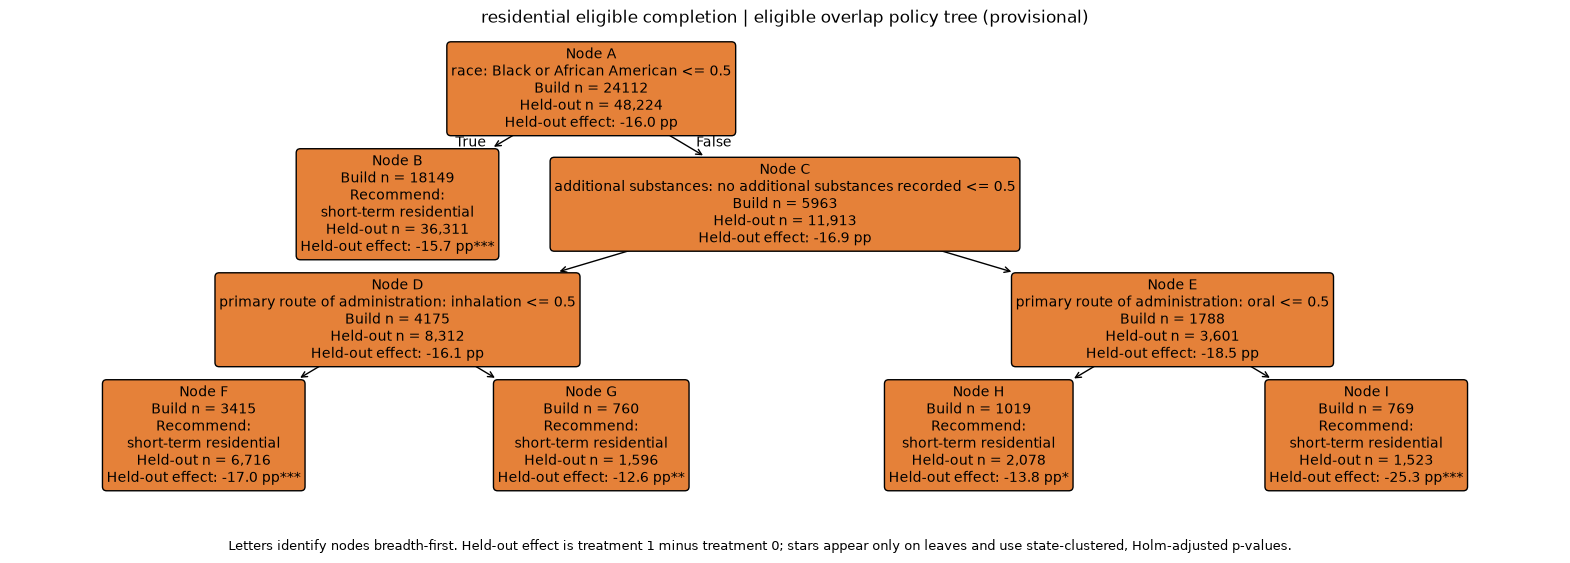

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_eligible,tree,48224,0.622752,0.0,39808.0625
1,residential_eligible,always_0,48224,0.622752,0.0,39808.0625
2,residential_eligible,always_1,48224,0.462634,1.0,39808.0625


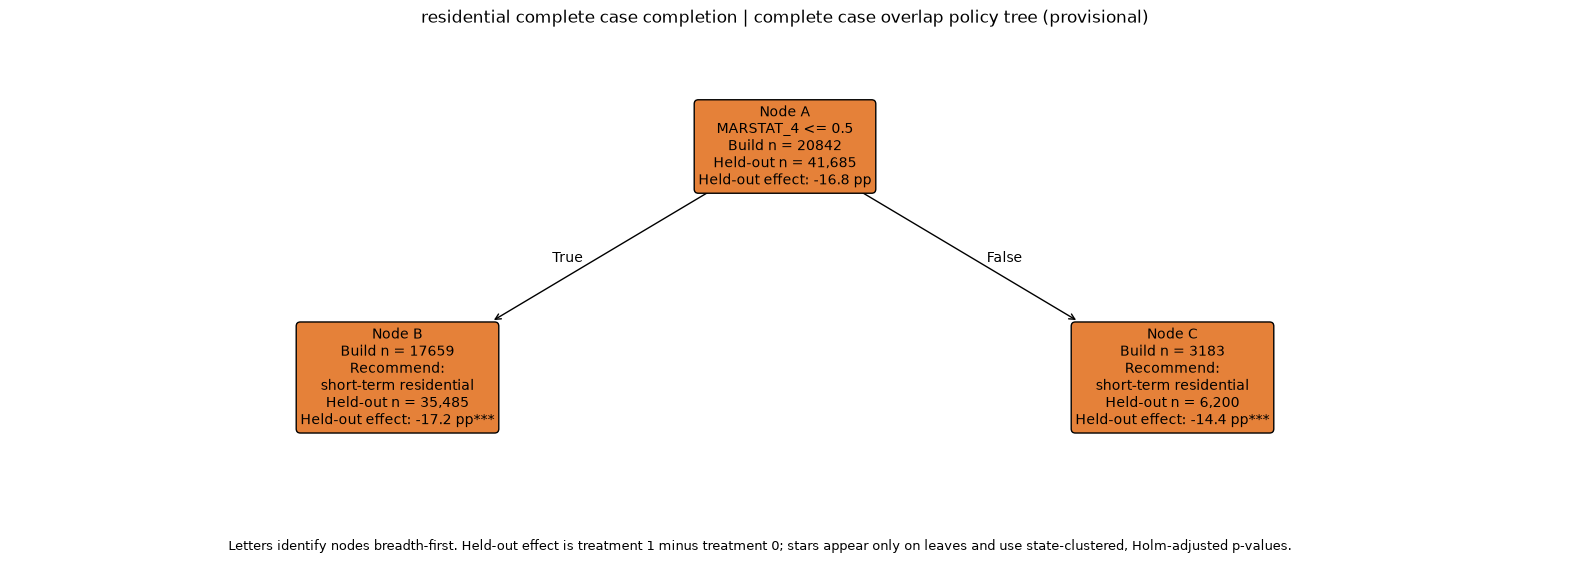

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_complete_case,tree,41685,0.642171,0.0,34420.125
1,residential_complete_case,always_0,41685,0.642171,0.0,34420.125
2,residential_complete_case,always_1,41685,0.473785,1.0,34420.125


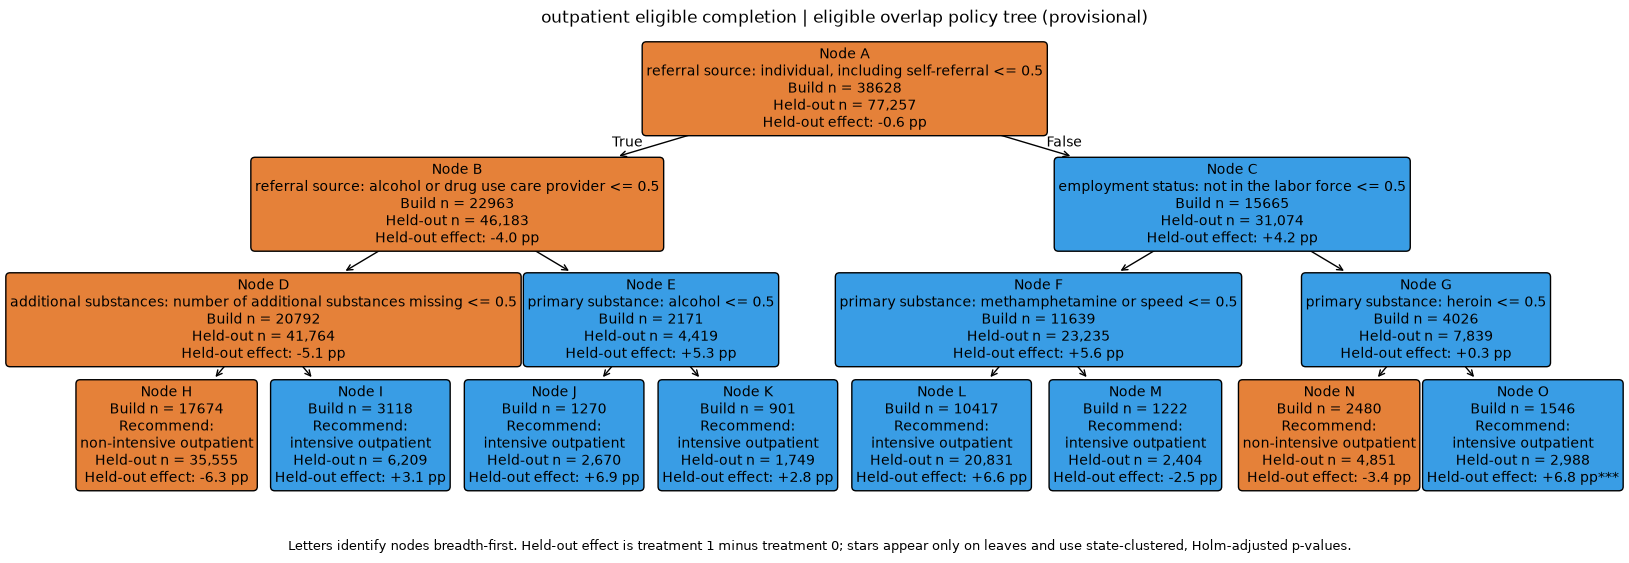

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_eligible,tree,77257,0.332439,0.476992,72082.007812
1,outpatient_eligible,always_0,77257,0.307499,0.000000,72082.007812
2,outpatient_eligible,always_1,77257,0.301067,1.000000,72082.007812


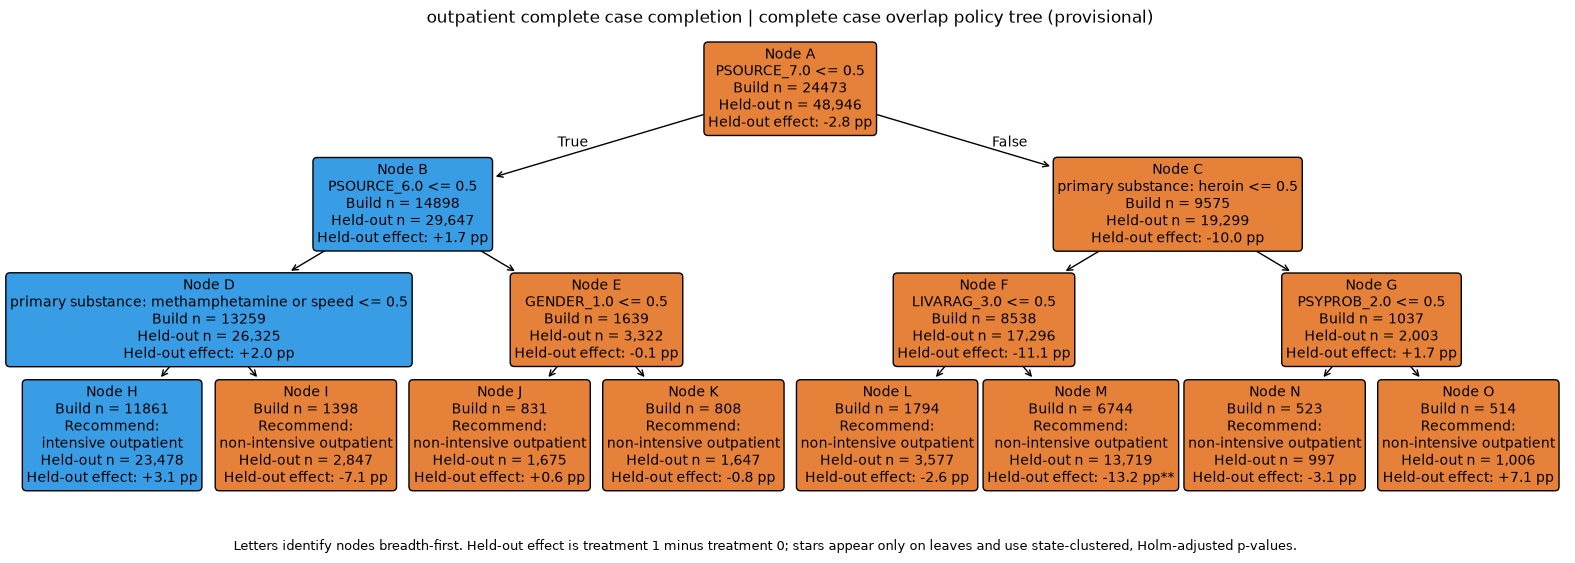

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_complete_case,tree,48946,0.362799,0.479671,46294.148438
1,outpatient_complete_case,always_0,48946,0.347689,0.000000,46294.148438
2,outpatient_complete_case,always_1,48946,0.319621,1.000000,46294.148438


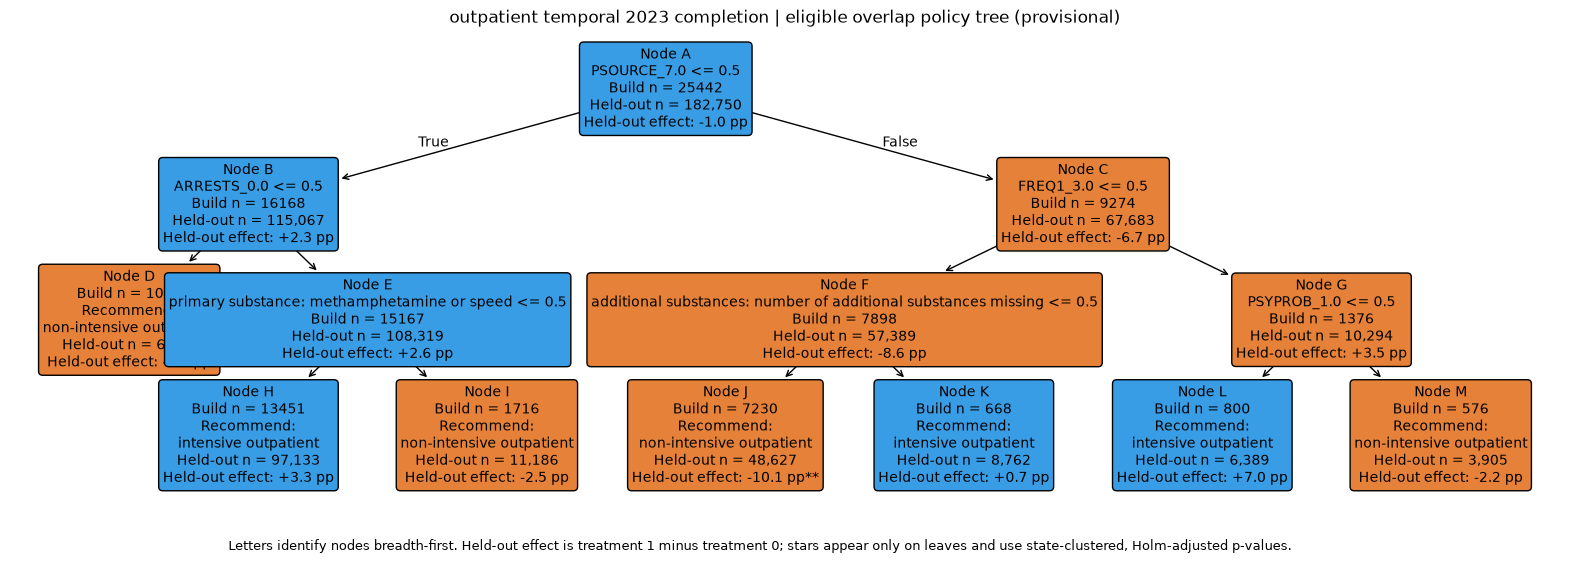

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_temporal_2023,tree,182750,0.328373,0.614413,170287.328125
1,outpatient_temporal_2023,always_0,182750,0.308048,0.000000,170287.328125
2,outpatient_temporal_2023,always_1,182750,0.298534,1.000000,170287.328125


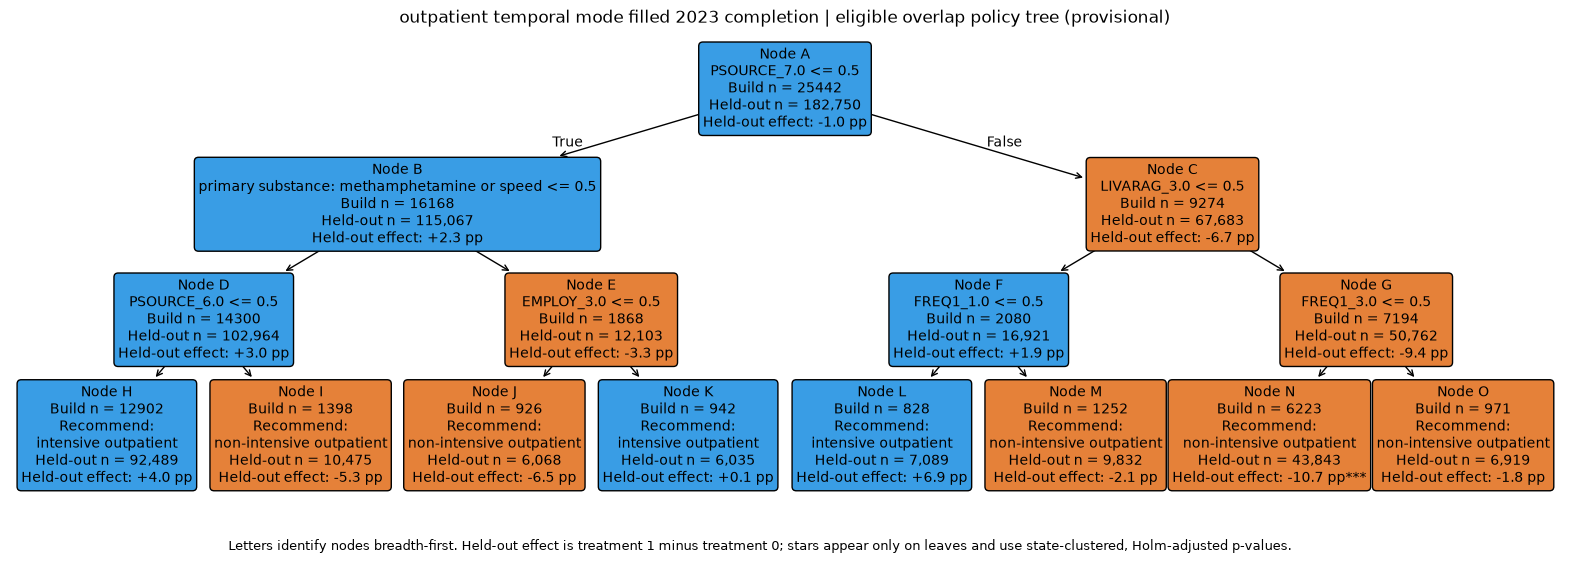

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_temporal_mode_filled_2023,tree,182750,0.331053,0.57791,170287.328125
1,outpatient_temporal_mode_filled_2023,always_0,182750,0.308048,0.00000,170287.328125
2,outpatient_temporal_mode_filled_2023,always_1,182750,0.298534,1.00000,170287.328125


In [3]:
results=[];values=[]
for branch in ('residential','outpatient'):
    for scope in ('eligible','complete_case'):
        info=dict(BRANCHES[branch])
        info['file']=info['eligible_file'] if scope=='eligible' else info['complete_case_file']
        info['expected_n']=info[f'{scope}_n']
        d=prepare_sample(branch,info,scope)
        tag=f'{branch}_{scope}'
        roles=split_positions(d)
        split=pd.DataFrame({'episode_source_id':d.episode_source_id,'role':np.full(len(d),'',dtype=object)})
        for role,index in roles.items():split.loc[index,'role']=role
        assert split.role.isin(['train','build','test']).all()
        split.to_csv(RUN/f'{tag}_split.csv.gz',index=False)
        result,value=fit_branch(tag,info,d,roles,scope)
        results.append(result);values.append(value)
        review.figure(f'{tag} completion policy tree',RUN/tag/'policy_tree.png')
        review.table(f'{tag} held-out CATE quartiles',pd.read_csv(RUN/tag/'cate_quartile_calibration.csv'))
        review.table(f'{tag} held-out policy gain by state',pd.read_csv(RUN/tag/'policy_gain_by_state.csv'))
        review.table(f'{tag} held-out policy gain by year',pd.read_csv(RUN/tag/'policy_gain_by_year.csv'))
        if (RUN/tag/'policy_gain_by_additional_substances_missing.csv').is_file():
            review.table(f'{tag} gain by admission-field missingness',pd.read_csv(RUN/tag/'policy_gain_by_additional_substances_missing.csv'))
        review.mark(f'Fit and evaluate {tag} completion tree')
        del d,split,roles;gc.collect()
# Separate out-of-year validation; the 2023 outcomes are not used for fitting or tree selection.
info=dict(BRANCHES['outpatient']);info['file']=info['eligible_file'];info['expected_n']=info['eligible_n']
d=prepare_sample('outpatient',info,'eligible')
positions=np.arange(len(d));historical=positions[d.DISYR.eq(2022).to_numpy()];future=positions[d.DISYR.eq(2023).to_numpy()]
assert len(historical)+len(future)==len(d) and len(future)>0
strata=d.STFIPS.astype(str)+'_'+d.treatment.astype(int).astype(str)
train,build=train_test_split(historical,test_size=.25,random_state=44,stratify=strata.iloc[historical])
roles={'train':np.sort(train),'build':np.sort(build),'test':np.sort(future)}
assert d.DISYR.iloc[roles['train']].eq(2022).all() and d.DISYR.iloc[roles['build']].eq(2022).all()
assert d.DISYR.iloc[roles['test']].eq(2023).all()
tag='outpatient_temporal_2023'
split=pd.DataFrame({'episode_source_id':d.episode_source_id,'role':np.full(len(d),'',dtype=object)})
for role,index in roles.items():split.loc[index,'role']=role
assert split.role.isin(['train','build','test']).all()
split.to_csv(RUN/f'{tag}_split.csv.gz',index=False)
result,value=fit_branch(tag,info,d,roles,'eligible',temporal=True)
results.append(result);values.append(value)
review.figure(f'{tag} completion policy tree',RUN/tag/'policy_tree.png')
review.table(f'{tag} held-out gain by state',pd.read_csv(RUN/tag/'policy_gain_by_state.csv'))
review.table(f'{tag} gain by admission-field missingness',pd.read_csv(RUN/tag/'policy_gain_by_additional_substances_missing.csv'))
review.mark('Fit 2022 outpatient tree and evaluate on 2023')
# Post-hoc representation sensitivity on the same 2022/2023 split; never label it confirmatory.
tag='outpatient_temporal_mode_filled_2023'
split.to_csv(RUN/f'{tag}_split.csv.gz',index=False)
result,value=fit_branch(tag,info,d,roles,'eligible',temporal=True,policy_mode_impute=True)
results.append(result);values.append(value)
review.figure(f'{tag} completion policy tree',RUN/tag/'policy_tree.png')
review.table(f'{tag} held-out gain by state',pd.read_csv(RUN/tag/'policy_gain_by_state.csv'))
review.table(f'{tag} gain by admission-field missingness',pd.read_csv(RUN/tag/'policy_gain_by_additional_substances_missing.csv'))
review.mark('Evaluate mode-filled policy-input sensitivity on 2023')
del d,split,roles;gc.collect()


In [4]:
summary=pd.concat(values,ignore_index=True)
summary.to_csv(RUN/'policy_value_summary.csv',index=False)
review.table('Held-out overlap-population policy values',summary)
review.note('Eligible analysis treats missing admission covariates as observed categories; complete-case analysis changes the population. Both remain provisional. State completion coding, unmeasured confounding, missing-value information, and state dependence limit interpretation. Frequency trees were not fit.')
review.mark('Save policy trees and held-out summaries')
report_path=review.export()
manifest={'status':'eligible_observed_information_and_complete_case_policy_sensitivity_inference_pending',
 'created_at':datetime.now().astimezone().isoformat(),
 'sources':{branch:{'preparation_run':info['source'].name,'preparation_manifest_sha256':sha(info['source']/'manifest.json'),
                    'review_run':(res_review if branch=='residential' else out_review).name} for branch,info in BRANCHES.items()},
 'software':{'python':platform.python_version(),'econml':__import__('importlib.metadata',fromlist=['version']).version('econml')},
 'design':{'train_fraction':.6,'tree_build_fraction':.2,'evaluation_fraction':.2,'split_seed':[42,43],
           'policy_target':'e(X)*(1-e(X)) overlap population','policy_tree_max_depth':3,
           'missing_covariates':'literal missing category in eligible analysis; complete-case sensitivity',
           'policy_cost_threshold':0,'temporal_validation':'2022 train and tree build; 2023 evaluation with state-only adjustment in nuisance models',
           'mode_filled_policy_sensitivity':'post-hoc; same 2023 evaluation outcomes already inspected',
           'leaf_stars':'held-out treatment-1-minus-treatment-0 effect; state-clustered t tests; Holm-adjusted within tree',
           'inference':'leaf stars exploratory; final causal inference pending'},
 'results':results,'summary_sha256':sha(RUN/'policy_value_summary.csv'),
 'split_sha256':{item['branch']:sha(RUN/f"{item['branch']}_split.csv.gz") for item in results},
 'summary_report':str(report_path.relative_to(ROOT)),
 'limits':['Missing-as-category does not recover unobserved covariate values; final missing-data sensitivity remains pending.',
           'Complete-case membership differs greatly across states from the eligible population.',
           'Outpatient completion/transfer coding across states and years is not yet harmonized.',
           'Only episode IDs are available; repeated patients cannot be linked.',
           'A tree from observational data is not a validated clinical decision rule.',
           'State jackknife standard errors are descriptive stability checks with few clusters, not validated confidence intervals.',
           'The 2022-to-2023 validation is observational and does not establish transport across reporting changes or valid state-cluster inference.']}
(RUN/'manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
print('Saved:',RUN/'manifest.json')
print('Review:',report_path)

Saved: /Users/researcher/code_projects/Causal Discovery /code/project_code/notebooks/code_0927/S1/outputs/S1_02_policy_trees_20260926_195240_351369/manifest.json
Review: /Users/researcher/code_projects/Causal Discovery /code/project_code/notebooks/code_0927/S1/reports/S1_02_policy_trees_20260926_200444_509544.html
